## Inventory Analysis Project : Python 
### Prepared by : Yash Takalkar

This project focuses on inventory data analysis by connecting Python to a Microsoft SQL Server database (SSMS) and retrieving inventory records using Pandas. The collected data is cleaned and transformed through various Pandas operations, including handling missing values, removing duplicates, filtering, sorting, grouping, and creating new features. After preprocessing, exploratory data analysis is performed to identify trends and patterns in inventory, orders, and warehouse performance. Finally, the processed data is visualized using Matplotlib and Seaborn through different charts and graphs, providing meaningful insights for better inventory management and decision-making.

## 1) Connecting database 

The SSMS database is connected to Jupyter Notebook using the pyodbc library and an SQL Server ODBC driver. Pandas executes SQL queries to import the database table into a DataFrame for data cleaning and transformation. The processed data is then visualized using Matplotlib and Seaborn to generate meaningful charts and insights.

In [5]:
import pyodbc
import pandas as pd

In [7]:
conn = pyodbc.connect(
    "DRIVER={ODBC Driver 17 for SQL Server};"
    "SERVER=LAPPY;"
    "DATABASE=Project;"
    "Trusted_Connection=yes;"
)

print("Connection successful!")

Connection successful!


## 2) Extracting Data

The data is loaded into Jupyter Notebook by the help of read_sql() function. 
The pd.read_sql(query, conn) extracts data from database

In [8]:
import pandas as pd
query = "SELECT * FROM Inventory"
df = pd.read_sql(query, conn)
df.head()

C:\Users\Yash\AppData\Local\Temp\ipykernel_31580\3825460268.py:3: UserWarning: pandas only supports SQLAlchemy connectable (engine/connection) or database string URI or sqlite3 DBAPI2 connection. Other DBAPI2 objects are not tested. Please consider using SQLAlchemy.
  df = pd.read_sql(query, conn)


,Order_ID,Date_order,Product_Name,Stock,Orders,Status_Order,Warehouse
0,ORD001,2024-01-05,Laptop,50.0,10.0,Delivered,Pune
1,ORD002,2024-01-06,Mouse,200.0,35.0,Pending,Mumbai
2,ORD003,2024-01-07,Keyboard,150.0,20.0,Delivered,Chennai
3,ORD004,2024-01-08,Monitor,80.0,15.0,Cancelled,Bangalore
4,ORD005,2024-01-09,Printer,40.0,8.0,Shipped,Pune


## 3) Data Cleaning by using pandas

In [9]:
# Full information about data
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 120 entries, 0 to 119
Data columns (total 7 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Order_ID      120 non-null    object 
 1   Date_order    120 non-null    object 
 2   Product_Name  120 non-null    object 
 3   Stock         113 non-null    float64
 4   Orders        114 non-null    float64
 5   Status_Order  120 non-null    object 
 6   Warehouse     120 non-null    object 
dtypes: float64(2), object(5)
memory usage: 6.7+ KB


In [10]:
#Handling missing values
print("Handling Missing Values : ")
null = df.isnull().sum()
print(null)
print("--------------------------------------------------------------------------------------------------")
df['Stock'] = df['Stock'].fillna(df['Stock'].mean())
df['Orders'] = df['Orders'].fillna(df['Orders'].median())
null2 = df.isnull().sum()
print("After filling null values \n \n",null2)

Handling Missing Values : 
Order_ID        0
Date_order      0
Product_Name    0
Stock           7
Orders          6
Status_Order    0
Warehouse       0
dtype: int64
--------------------------------------------------------------------------------------------------
After filling null values 
 
 Order_ID        0
Date_order      0
Product_Name    0
Stock           0
Orders          0
Status_Order    0
Warehouse       0
dtype: int64


In [11]:
#Handling Duplicates 
dup = df.duplicated().sum()
print(dup)

0


In [12]:
# Checking data types
df.dtypes

Order_ID         object
Date_order       object
Product_Name     object
Stock           float64
Orders          float64
Status_Order     object
Warehouse        object
dtype: object

In [13]:
# Change Data type of Date_order
date = df['Date_order'] = pd.to_datetime(df['Date_order'])
date

0     2024-01-05
1     2024-01-06
2     2024-01-07
3     2024-01-08
4     2024-01-09
         ...    
115   2024-04-29
116   2024-04-30
117   2024-05-01
118   2024-05-02
119   2024-05-03
Name: Date_order, Length: 120, dtype: datetime64[ns]

In [14]:
# Replacing Warehouse (Bangalore to bengaluru)
rep = df['Warehouse'] = df['Warehouse'].replace(
    'Bangalore',
    'Bengaluru'
)
rep

0           Pune
1         Mumbai
2        Chennai
3      Bengaluru
4           Pune
         ...    
115    Bengaluru
116         Pune
117       Mumbai
118      Chennai
119    Bengaluru
Name: Warehouse, Length: 120, dtype: object

In [15]:
# Summary Statistics
df.describe()

,Date_order,Stock,Orders
count,120,120.000000,120.000000
mean,2024-03-04 12:00:00,105.973451,23.000000
min,2024-01-05 00:00:00,30.000000,8.000000
25%,2024-02-03 18:00:00,69.500000,16.000000
50%,2024-03-04 12:00:00,101.000000,22.000000
75%,2024-04-03 06:00:00,138.500000,29.000000
max,2024-05-03 00:00:00,225.000000,45.000000
std,NaN,48.238807,8.893393


## 4) Data Visualization

Using matplotlib and seaborn libraries for data visualization

### Which warehouse receives the highest number of orders?

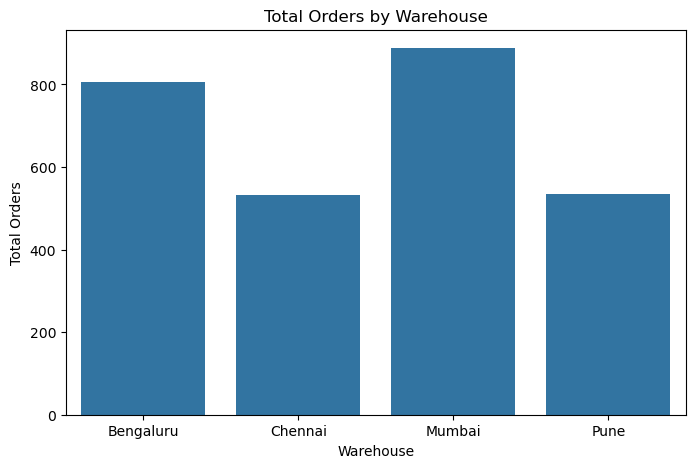

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

warehouse_orders = df.groupby('Warehouse')['Orders'].sum().reset_index()

plt.figure(figsize=(8,5))
sns.barplot(data=warehouse_orders,
            x='Warehouse',
            y='Orders')

plt.title("Total Orders by Warehouse")
plt.xlabel("Warehouse")
plt.ylabel("Total Orders")
plt.show()

### Which products are ordered the most?

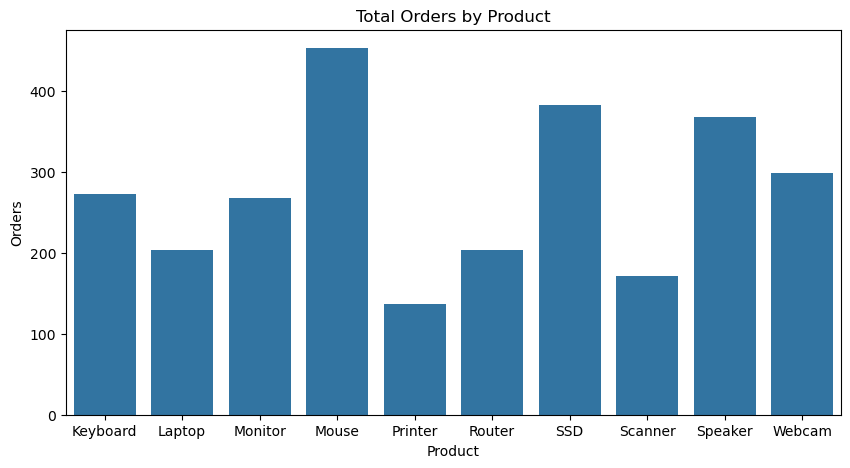

In [20]:
product_orders = df.groupby('Product_Name')['Orders'].sum().reset_index()

plt.figure(figsize=(10,5))
sns.barplot(data=product_orders,
            x='Product_Name',
            y='Orders')

plt.title("Total Orders by Product")
plt.xlabel("Product")
plt.ylabel("Orders")
plt.show()

### Which warehouse have highest percentage of orders?

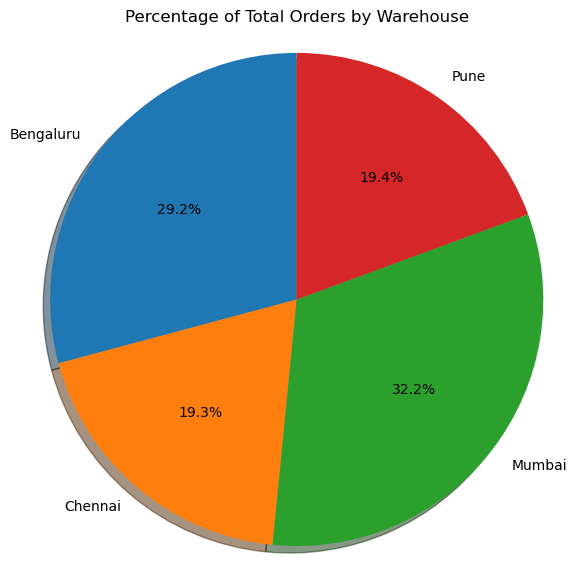

In [18]:
warehouse_orders = df.groupby('Warehouse')['Orders'].sum()

plt.figure(figsize=(7,7))

plt.pie(
    warehouse_orders,
    labels=warehouse_orders.index,
    autopct='%1.1f%%',
    startangle=90,
    shadow=True
)

plt.title("Percentage of Total Orders by Warehouse")
plt.axis('equal')  

plt.show()

# Project Report
### Project Title

Inventory Data Cleaning and Visualization using Python and SQL Server

### Prepared By

Name: Yash Takalkar

### Project Objective

The objective of this project is to connect SQL Server with Python, retrieve inventory data, perform data cleaning using Pandas, and create meaningful visualizations using Matplotlib and Seaborn. The project aims to improve data quality and provide useful insights from the inventory dataset.

### Tools and Technologies Used
Python
Jupyter Notebook
Pandas
Matplotlib
Seaborn
SQL Server Management Studio (SSMS)
pyodbc

### Methodology

The project was completed using the following steps:

Connected SQL Server with Python using pyodbc.
Imported inventory data into a Pandas DataFrame.
Inspected the dataset using head(), info(), and describe().
Checked and handled missing values and duplicate records.
Converted the Date_order column into datetime format.
Standardized warehouse names for consistency.
Created visualizations to analyze warehouse performance and product orders.

### Key Findings

The SQL Server database was successfully connected to Python.

The dataset was cleaned by handling missing values, duplicates, and data type inconsistencies.

Visualizations helped compare warehouse performance and product order distribution.

The cleaned data is suitable for further reporting and business analysis.

### Conclusion

This project demonstrates how Python can be integrated with SQL Server to perform data cleaning and visualization efficiently. Using Pandas, Matplotlib, and Seaborn, the inventory data was analyzed and presented through clear visualizations, making it easier to understand warehouse performance and inventory trends.